# Himalayan Mountaineering Expeditions
### Exploratory Data Analysis & Dashboard

## Step 1: Dataset
- **Title:** The History of Himalayan Mountaineering Expeditions
- **Source:** (https://github.com/rfordatascience/tidytuesday/tree/main/data/2025/2025-01-21)
- **Files:** `exped_tidy.csv` (882 expeditions, 69 columns) and `peaks_tidy.csv` (480 mountains, 29 columns)

## Step 2: Problem Definition

### What is the dataset about?
This dataset contains records of 882 mountaineering expeditions in the Nepal Himalaya from 2020 to 2024, including Mount Everest. It describes each expedition's season, team size, climbing company, number of hired guides, oxygen use, result and deaths. A second file describes each mountain, such as its name and height.

About 3 in 10 expeditions fail, and some end in deaths. This project finds what makes the difference between a successful, safe expedition and a failed or dangerous one.

### What main questions will I explore?
1. Does using oxygen increase the chance of success?
2. Are bigger teams more successful than smaller teams?
3. Do hired guides (Sherpas) help expeditions succeed?
4. Which season is the best for climbing, and which is the most dangerous?
5. Are higher mountains harder and more dangerous to climb?
6. Which climbing companies have the best results?
7. What are the main reasons expeditions fail?

### What insights do I expect to uncover?
I expect oxygen use, team size and the number of guides to be strongly related to success. I expect weather to be the main reason for failure, and higher mountains to have more deaths. These insights can help climbers plan safer and more successful expeditions.

### Target audience
Climbers who are planning a Himalayan expedition. The dashboard helps them decide which mountain, season and company to choose, how big their team should be, how many guides to hire and whether to use oxygen, based on the results of past expeditions.

## Step 3: Data Loading & structure

### 3.1 Import libraries

In [171]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [172]:
pd.set_option("display.max_columns", None)   #show all columns instead of "..."
pd.set_option("display.max_rows", None)   #show all rows instead of "..."

### 3.2 Load the data
The expeditions file is opened with `encoding="latin1"` because it contains special characters.

In [173]:
exped = pd.read_csv("../Data/exped_tidy.csv", encoding="latin1")
peaks = pd.read_csv("../Data/peaks_tidy.csv", encoding="latin1")

### 3.3 First 5 rows

In [174]:
exped.head()

,EXPID,PEAKID,YEAR,SEASON,SEASON_FACTOR,HOST,HOST_FACTOR,ROUTE1,ROUTE2,ROUTE3,ROUTE4,NATION,LEADERS,SPONSOR,SUCCESS1,SUCCESS2,SUCCESS3,SUCCESS4,ASCENT1,ASCENT2,ASCENT3,ASCENT4,CLAIMED,DISPUTED,COUNTRIES,APPROACH,BCDATE,SMTDATE,SMTTIME,SMTDAYS,TOTDAYS,TERMDATE,TERMREASON,TERMREASON_FACTOR,TERMNOTE,HIGHPOINT,TRAVERSE,SKI,PARAPENTE,CAMPS,ROPE,TOTMEMBERS,SMTMEMBERS,MDEATHS,TOTHIRED,SMTHIRED,HDEATHS,NOHIRED,O2USED,O2NONE,O2CLIMB,O2DESCENT,O2SLEEP,O2MEDICAL,O2TAKEN,O2UNKWN,OTHERSMTS,CAMPSITES,ROUTEMEMO,ACCIDENTS,ACHIEVMENT,AGENCY,COMRTE,STDRTE,PRIMRTE,PRIMMEM,PRIMREF,PRIMID,CHKSUM
0,EVER20101,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,NaN,China,Tibetan Rope-Fixing,Tibetan Rope-Fixing Everest North 2020,True,False,False,False,NaN,NaN,NaN,NaN,False,False,NaN,Lhasa->Tingri->Everest BC,NaN,2020-05-26,1515.0,0,0,NaN,1,Success (main peak),NaN,8849,False,False,False,3,0,0,0,0,6,6,0,False,True,False,True,False,True,False,False,False,NaN,"BC,ABC,C1,C2,C3,Smt(26/05)",NaN,NaN,NaN,Holy Mountain Adventure,True,True,False,False,False,NaN,2465291
1,EVER20102,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,NaN,China,Ci Luo (Tselo),Chinese Mount Everest Survey Team,True,False,False,False,NaN,NaN,NaN,NaN,False,False,NaN,NaN,NaN,2020-05-27,945.0,0,0,NaN,1,Success (main peak),NaN,8849,False,False,False,3,0,12,8,0,0,0,0,False,True,False,True,False,True,False,False,False,NaN,"BC,ABC,C1,C2,C3,Smt(27/05)",221011.0,NaN,NaN,NaN,True,True,False,False,False,NaN,2465292
2,EVER20103,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,NaN,China,Tsering Samdrup,Holy Mountain Adventure Everest Expedition 2020,True,False,False,False,NaN,NaN,NaN,NaN,False,False,NaN,Lhasa->Tingri->Everest BC,2020-04-23,2020-05-28,545.0,35,38,2020-05-31,1,Success (main peak),NaN,8849,False,False,False,3,0,20,14,0,22,21,0,False,True,False,True,False,True,False,False,False,NaN,"BC(23/04,5200m),IC(26/04,5800m),ABC(05/01,6500...",203869.0,NaN,NaN,Holy Mountain Adventure,True,True,False,False,False,NaN,2465293
3,AMAD20301,AMAD,2020,3,Autumn,1,Nepal,SW Ridge,NaN,NaN,NaN,Nepal,Chhang Dawa Sherpa,Seven Summit Treks Ama Dablam Expedition 2020,True,False,False,False,NaN,NaN,NaN,NaN,False,False,"Canada, Czech Republic, France, Poland, Russia...",NaN,2020-11-09,2020-11-10,1300.0,1,0,NaN,1,Success (main peak),NaN,6814,False,False,False,2,0,14,9,0,19,14,0,False,False,True,False,False,False,False,False,False,NaN,"BC(09/11,4450m),C1(5600m),C2(5900m),Smt(10,12-...",NaN,NaN,NaN,Seven Summit Treks,True,False,False,False,False,NaN,2463299
4,AMAD20302,AMAD,2020,3,Autumn,1,Nepal,SW Ridge,NaN,NaN,NaN,USA,Garrett Madison,Madison Mountaineering Ama Dablam Expedition 2020,True,False,False,False,NaN,NaN,NaN,NaN,False,False,"Canada, Qatar",Lukla->Pangboche->Ama Dablam BC,2020-11-01,2020-11-10,1300.0,9,11,2020-11-12,1,Success (main peak),NaN,6814,False,False,False,2,0,6,6,0,8,8,0,False,False,True,False,False,False,False,False,False,NaN,"BC(01/11,4700m),C1(04/11,5600m),C2(10/11,6000m...",29755.0,NaN,NaN,Himalayan Guides,True,False,False,False,False,NaN,2463299


In [175]:
peaks.head()

,PEAKID,PKNAME,PKNAME2,LOCATION,HEIGHTM,HEIGHTF,HIMAL,HIMAL_FACTOR,REGION,REGION_FACTOR,OPEN,UNLISTED,TREKKING,TREKYEAR,RESTRICT,PHOST,PHOST_FACTOR,PSTATUS,PSTATUS_FACTOR,PEAKMEMO,PYEAR,PSEASON,PEXPID,PSMTDATE,PCOUNTRY,PSUMMITERS,PSMTNOTE,REFERMEMO,PHOTOMEMO
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,6814,22356,12,Khumbu,2,Khumbu-Rolwaling-Makalu,True,False,False,NaN,NaN,1,Nepal only,2,Climbed,8.0,1961.0,1,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,13.0
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),5630,18471,12,Khumbu,2,Khumbu-Rolwaling-Makalu,True,False,False,NaN,Opened in 2002,1,Nepal only,2,Climbed,20.0,1953.0,1,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,8091,26545,1,Annapurna,5,Annapurna-Damodar-Peri,True,False,False,NaN,NaN,1,Nepal only,2,Climbed,23.0,1950.0,1,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,25.0,26.0
3,ANN2,Annapurna II,NaN,Annapurna Himal,7937,26040,1,Annapurna,5,Annapurna-Damodar-Peri,True,False,False,NaN,NaN,1,Nepal only,2,Climbed,31.0,1960.0,1,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,33.0,34.0
4,ANN3,Annapurna III,NaN,Annapurna Himal,7555,24787,1,Annapurna,5,Annapurna-Damodar-Peri,True,False,False,NaN,NaN,1,Nepal only,2,Climbed,35.0,1961.0,1,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,37.0


### 3.4 Shape

In [176]:
print("Expeditions:", exped.shape)
print("Peaks:", peaks.shape)

Expeditions: (882, 69)
Peaks: (480, 29)


### 3.5 Data types

In [177]:
exped.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 882 entries, 0 to 881
Data columns (total 69 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EXPID              882 non-null    object 
 1   PEAKID             882 non-null    object 
 2   YEAR               882 non-null    int64  
 3   SEASON             882 non-null    int64  
 4   SEASON_FACTOR      882 non-null    object 
 5   HOST               882 non-null    int64  
 6   HOST_FACTOR        882 non-null    object 
 7   ROUTE1             862 non-null    object 
 8   ROUTE2             43 non-null     object 
 9   ROUTE3             0 non-null      float64
 10  ROUTE4             0 non-null      float64
 11  NATION             882 non-null    object 
 12  LEADERS            882 non-null    object 
 13  SPONSOR            882 non-null    object 
 14  SUCCESS1           882 non-null    bool   
 15  SUCCESS2           882 non-null    bool   
 16  SUCCESS3           882 non

In [178]:
peaks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PEAKID          480 non-null    object 
 1   PKNAME          480 non-null    object 
 2   PKNAME2         257 non-null    object 
 3   LOCATION        479 non-null    object 
 4   HEIGHTM         480 non-null    int64  
 5   HEIGHTF         480 non-null    int64  
 6   HIMAL           480 non-null    int64  
 7   HIMAL_FACTOR    480 non-null    object 
 8   REGION          480 non-null    int64  
 9   REGION_FACTOR   480 non-null    object 
 10  OPEN            480 non-null    bool   
 11  UNLISTED        480 non-null    bool   
 12  TREKKING        480 non-null    bool   
 13  TREKYEAR        29 non-null     float64
 14  RESTRICT        275 non-null    object 
 15  PHOST           480 non-null    int64  
 16  PHOST_FACTOR    480 non-null    object 
 17  PSTATUS         480 non-null    int

### 3.6 Statistics

In [179]:
exped.describe(include='all') #to get a summary of all data types not just numeric

,EXPID,PEAKID,YEAR,SEASON,SEASON_FACTOR,HOST,HOST_FACTOR,ROUTE1,ROUTE2,ROUTE3,ROUTE4,NATION,LEADERS,SPONSOR,SUCCESS1,SUCCESS2,SUCCESS3,SUCCESS4,ASCENT1,ASCENT2,ASCENT3,ASCENT4,CLAIMED,DISPUTED,COUNTRIES,APPROACH,BCDATE,SMTDATE,SMTTIME,SMTDAYS,TOTDAYS,TERMDATE,TERMREASON,TERMREASON_FACTOR,TERMNOTE,HIGHPOINT,TRAVERSE,SKI,PARAPENTE,CAMPS,ROPE,TOTMEMBERS,SMTMEMBERS,MDEATHS,TOTHIRED,SMTHIRED,HDEATHS,NOHIRED,O2USED,O2NONE,O2CLIMB,O2DESCENT,O2SLEEP,O2MEDICAL,O2TAKEN,O2UNKWN,OTHERSMTS,CAMPSITES,ROUTEMEMO,ACCIDENTS,ACHIEVMENT,AGENCY,COMRTE,STDRTE,PRIMRTE,PRIMMEM,PRIMREF,PRIMID,CHKSUM
count,882,882,882.000000,882.000000,882,882.000000,882,862,43,0.0,0.0,882,882,882,882,882,882,882,29,1,0.0,0.0,882,882,582,328,409,795,365.000000,882.000000,882.000000,338,882.000000,882,209,882.000000,882,882,882,882.000000,882.000000,882.000000,882.000000,882.000000,882.000000,882.000000,882.000000,882,882,882,882,882,882,882,882,882,148,845,528.000000,12,25,857,882,882,882,882,882,67,8.820000e+02
unique,882,116,NaN,NaN,4,NaN,3,92,15,NaN,NaN,64,578,805,2,2,1,1,8,1,NaN,NaN,1,2,468,213,246,291,NaN,NaN,NaN,188,NaN,13,176,NaN,2,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2,2,2,2,2,144,770,NaN,12,24,181,2,2,2,1,2,62,NaN
top,YLNG24101,EVER,NaN,NaN,Spring,NaN,Nepal,S Col-SE Ridge,S Col-W Face,NaN,NaN,Nepal,Nirmal Purja,Seven Summit Treks Ama Dablam Expedition 2020,True,False,False,False,1st,5th,NaN,NaN,False,False,USA,Lukla->Namche->Lobuche->BC,2021-04-15,2021-05-23,NaN,NaN,NaN,2021-05-29,NaN,Success (main peak),Stopped at high fore-smt (8156m),NaN,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,False,False,False,False,False,False,Summited Lhotse (LHOT-221-04),No Smt,NaN,Bob Wood and Ang Nuru Sherpa injurd ice collap...,"1st ski descents of RATC, HUGO and Upche Dada;...",Seven Summit Treks,False,True,False,False,False,EVER21106,NaN
freq,1,189,NaN,NaN,462,NaN,855,171,21,NaN,NaN,130,19,3,624,848,882,882,14,1,NaN,NaN,882,880,15,30,11,24,NaN,NaN,NaN,9,NaN,628,20,NaN,873,861,882,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,736,473,463,476,871,811,874,870,878,2,17,NaN,1,2,120,445,468,870,882,821,2,NaN
mean,NaN,NaN,2022.252834,1.970522,NaN,1.032880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,962.564384,8.024943,8.998866,NaN,2.221088,NaN,NaN,6979.463719,NaN,NaN,NaN,2.521542,19.444444,8.192744,3.803855,0.040816,7.614512,4.038549,0.019274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,146087.189394,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.213338e+06
std,NaN,NaN,1.017786,1.032521,NaN,0.190723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,369.541681,12.094945,14.002473,NaN,2.649800,NaN,NaN,2321.385218,NaN,NaN,NaN,1.533615,218.251820,6.821315,4.768306,0.262120,9.117653,5.963442,0.167347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69081.426334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.452020e+05
min,NaN,NaN,2020.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2195.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.022000e+03
25%,NaN,NaN,2021.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,700.000000,0.000000,0.000000,NaN,1.000000,NaN,NaN,6714.750000,NaN,NaN,NaN,2.000000,0.000000,3.000000,0.000000,0.000000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,84473.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.463313e+06
50%,NaN,NaN,2022.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,920.000000,0.000000,0.000000,NaN,1.000000,NaN,NaN,7176.000000,NaN,NaN,NaN,3.000000,0.000000,6.000000,2.000000,0.000000,5.000000,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,165247.500000,NaN,NaN,NaN,NaN

In [180]:
peaks.describe(include='all')

,PEAKID,PKNAME,PKNAME2,LOCATION,HEIGHTM,HEIGHTF,HIMAL,HIMAL_FACTOR,REGION,REGION_FACTOR,OPEN,UNLISTED,TREKKING,TREKYEAR,RESTRICT,PHOST,PHOST_FACTOR,PSTATUS,PSTATUS_FACTOR,PEAKMEMO,PYEAR,PSEASON,PEXPID,PSMTDATE,PCOUNTRY,PSUMMITERS,PSMTNOTE,REFERMEMO,PHOTOMEMO
count,480,480,257,479,480.000000,480.000000,480.000000,480,480.000000,480,480,480,480,29.000000,275,480.000000,480,480.000000,480,475.000000,362.000000,480.000000,360,357,362,477,76,19.000000,78.000000
unique,480,480,254,408,NaN,NaN,NaN,20,NaN,7,2,2,2,NaN,27,NaN,6,NaN,2,NaN,NaN,NaN,360,157,83,354,71,NaN,NaN
top,KORL,Korlang Pari Tippa,Twins,Ohmi Kangri Himal (WNW of Kangchenjunga),NaN,NaN,NaN,Khumbu,NaN,Khumbu-Rolwaling-Makalu,True,False,False,NaN,Opened in 2014,NaN,Nepal only,NaN,Climbed,NaN,NaN,NaN,LNPS39201,Nov 02,"Japan, Nepal",Unclimbed,Illegal ascent,NaN,NaN
freq,1,1,2,6,NaN,NaN,NaN,78,NaN,132,385,415,449,NaN,96,NaN,307,NaN,368,NaN,NaN,NaN,1,7,62,90,4,NaN,NaN
mean,NaN,NaN,NaN,NaN,6648.977083,21814.245833,10.252083,NaN,3.802083,NaN,NaN,NaN,NaN,1918.758621,NaN,2.112500,NaN,1.766667,NaN,791.271579,1986.624309,1.581250,NaN,NaN,NaN,NaN,NaN,328.000000,380.064103
std,NaN,NaN,NaN,NaN,572.676102,1878.862588,5.536461,NaN,2.139302,NaN,NaN,NaN,NaN,365.364168,NaN,1.512595,NaN,0.423394,NaN,380.433475,25.147152,1.246985,NaN,NaN,NaN,NaN,NaN,201.345474,233.338968
min,NaN,NaN,NaN,NaN,5407.000000,17740.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,20.000000,NaN,1.000000,NaN,1.000000,NaN,8.000000,1909.000000,0.000000,NaN,NaN,NaN,NaN,NaN,25.000000,13.000000
25%,NaN,NaN,NaN,NaN,6235.000000,20456.000000,6.000000,NaN,2.000000,NaN,NaN,NaN,NaN,1978.000000,NaN,1.000000,NaN,2.000000,NaN,472.500000,1964.000000,1.000000,NaN,NaN,NaN,NaN,NaN,170.500000,178.250000
50%,NaN,NaN,NaN,NaN,6552.500000,21497.500000,11.000000,NaN,4.000000,NaN,NaN,NaN,NaN,1978.000000,NaN,1.000000,NaN,2.000000,NaN,865.000000,1983.500000,1.000000,NaN,NaN,NaN,NaN,NaN,304.000000,376.500000
75%,NaN,NaN,NaN,NaN,6900.500000,22639.750000,15.000000,NaN,6.000000,NaN,NaN,NaN,NaN,2002.000000,NaN,4.000000,NaN,2.000000,NaN,1115.000000,2010.750000,3.000000,NaN,NaN,NaN,NaN,NaN,491.500000,552.750000


### 3.7 Missing values

In [181]:
missing_exped = pd.DataFrame({
    "missing_count": exped.isnull().sum(),                         #how many values are missing
    "missing_percent": (exped.isnull().sum() / len(exped) * 100)   #percent missing
})
missing_exped.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
ROUTE4,882,100.000000
ASCENT4,882,100.000000
ASCENT3,882,100.000000
ROUTE3,882,100.000000
ASCENT2,881,99.886621
ACCIDENTS,870,98.639456
ACHIEVMENT,857,97.165533
ASCENT1,853,96.712018
ROUTE2,839,95.124717
PRIMID,815,92.403628


In [182]:
missing_peaks = pd.DataFrame({
    "missing_count": peaks.isnull().sum(),
    "missing_percent": (peaks.isnull().sum() / len(peaks) * 100)
})
missing_peaks.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
REFERMEMO,461,96.041667
TREKYEAR,451,93.958333
PSMTNOTE,404,84.166667
PHOTOMEMO,402,83.750000
PKNAME2,223,46.458333
RESTRICT,205,42.708333
PSMTDATE,123,25.625000
PEXPID,120,25.000000
PYEAR,118,24.583333
PCOUNTRY,118,24.583333


### Summary of Step 3

**1. Size** (found with `shape`)
- The expeditions file has 882 rows and 69 columns.
- The peaks file has 480 rows and 29 columns.

**2. First look at the rows** (found with `head()`)
- Each row in the expeditions file is one expedition, and each row in the peaks file is one mountain.
- Both files share the `PEAKID` column, so they can be joined.
- Some columns show the same information twice, as a number and as a name (for example `SEASON` = 1 and `SEASON_FACTOR` = Spring).
- Some columns contain long written notes instead of values (for example `TERMNOTE` and `ACCIDENTS`).

**3. Data types** (found with `info()`)
- The expeditions file has 22 number columns, 24 text columns and 23 boolean columns.
- The peaks file has 14 text columns, 7 integer columns, 5 decimal columns and 3 boolean columns.

**4. Statistics** (found with `describe()`)
- Mountain heights (`HEIGHTM`) range from 5,407 m to 8,849 m (Mount Everest).
- The minimum of `TOTDAYS`, `SMTDAYS` and `HIGHPOINT` is 0, which is not possible for a real expedition.
- The minimum of `TOTMEMBERS` is 0, which needs to be checked.
- Deaths are rare: the average of `MDEATHS` and `HDEATHS` is almost 0, with a maximum of 4.

**5. Missing values** (found with `isnull().sum()`)
- 4 columns are completely empty: `ROUTE3`, `ROUTE4`, `ASCENT3` and `ASCENT4`.
- 16 columns are more than half empty, mostly extra routes, dates and written notes.
- In the peaks file, the basic information about each mountain (name, height and mountain range) has no missing values. Most missing values are in extra details, such as notes, second names, permit information and the history of the first ascent. Some mountains have never been climbed, so their first-ascent information is empty.

## Step 4: Data Cleaning

### 4.1 Drop the columns I don't need
The expeditions file has 69 columns and the peaks file has 29, but most of them do not help answer my questions.
I will keep only the columns I need and drop the rest for the reasons below.

#### a) Columns that are more than 50% empty

In [183]:
#percent of missing values in each column
missing_percent = exped.isnull().sum() / len(exped) * 100

#columns that are more than 50% empty
mostly_empty = missing_percent[missing_percent > 50].index
print(list(mostly_empty))

['ROUTE2', 'ROUTE3', 'ROUTE4', 'ASCENT1', 'ASCENT2', 'ASCENT3', 'ASCENT4', 'APPROACH', 'BCDATE', 'SMTTIME', 'TERMDATE', 'TERMNOTE', 'OTHERSMTS', 'ACCIDENTS', 'ACHIEVMENT', 'PRIMID']


In [184]:
#drop the columns that are more than 50% empty
exped = exped.drop(columns=mostly_empty)
print(exped.shape)   #(882, 53)

(882, 53)


**Decision:** 16 columns are more than 50% empty. Even if they were complete, they would not help answer my questions, so I drop them:

| Columns | What they contain | Why I don't need them |
|---|---|---|
| `ROUTE2`, `ROUTE3`, `ROUTE4` | Extra climbing routes the expedition tried | Most expeditions use only one route. My questions are about oxygen, team size, guides, season and height, not about which route was taken. |
| `ASCENT1`, `ASCENT2`, `ASCENT3`, `ASCENT4` | How many times the route had been climbed before (e.g. "2nd" = second time in history) | This is a historical record of the route. It does not tell me whether the expedition succeeded or why, and it is only written for rare routes. |
| `BCDATE`, `TERMDATE`, `SMTTIME` | The exact date they reached base camp, the exact date the trip ended, and the hour they reached the summit | I already have simpler columns for this: `YEAR` and `SEASON_FACTOR` tell me when, and `TOTDAYS` tells me how long. I don't need the exact day or hour. |
| `APPROACH` | The trip to reach base camp before the climb starts, e.g. "Lhasa -> Tingri -> Everest base camp" | It is 63% empty and written as text (213 different paths), so it cannot be grouped. The path depends on the mountain and the side it is climbed from, which is already in `HOST_FACTOR` (Nepal or China). |
| `TERMNOTE` | A sentence explaining why the expedition ended, e.g. "Abandoned at 6650 m due to high winds" | The same reason is already given in a short form in `TERMREASON_FACTOR` (e.g. "Bad weather") |
| `OTHERSMTS` | Other mountains climbed on the same trip, e.g. "Climbed Lobuche" | It is about other mountains, not the main mountain I am analysing |
| `ACCIDENTS` | A description of accidents, e.g. "Two climbers injured in an ice collapse" | Deaths are already counted as numbers in `MDEATHS` and `HDEATHS` |
| `ACHIEVMENT` | Special records, e.g. "1st Arabic woman to summit Ama Dablam" | It is a rare personal record and does not explain why an expedition succeeded |
| `PRIMID` | A number that links a small expedition to a bigger "main" expedition | It is only used to organise the database. It tells me nothing about the climb (success, team size, oxygen). |

#### b) Text columns with a different value for almost every expedition

In [185]:
#number of different values in each text column (out of 882 expeditions)
print(exped[["SPONSOR", "CAMPSITES", "LEADERS", "COUNTRIES"]].nunique())

SPONSOR      805
CAMPSITES    770
LEADERS      578
COUNTRIES    468
dtype: int64


In [186]:
#drop the text columns that have a different value for almost every expedition
exped = exped.drop(columns=["SPONSOR", "CAMPSITES", "LEADERS", "COUNTRIES"])
print(exped.shape)   #(882, 49)

(882, 49)


To compare expeditions, a column needs to repeat the same values so they can be grouped. These columns have a different value for almost every one of the 882 expeditions, so they cannot be grouped or compared:

| Column | What it contains | Different values (of 882) | Why I don't need it |
|---|---|---|---|
| `SPONSOR` | The name of the expedition, e.g. "Madison Mountaineering Everest 2021" | 805 | Almost every expedition has its own name, like a title |
| `CAMPSITES` | The camps the team set up on the way to the summit, with dates and heights, e.g. "BC(23/04,5200m), C1(25/05,7028m), Smt(28/05)" | 770 | Each expedition writes it in a different format, so it cannot be grouped. My questions only need the number of days and whether they reached the summit |
| `LEADERS` | The names of the expedition leaders | 578 | Personal names that appear only once or twice; they cannot be compared and are not needed |
| `COUNTRIES` | Other nationalities in the team, e.g. "Canada, France, Poland" | 468 | Several countries in one cell, and 34% empty. `NATION` already gives the main nationality |

#### c) Columns only known after the expedition (data leakage)
My audience is climbers who plan **before** the trip, so I need columns they can decide or know before they go.
Some columns are only known **after** the expedition and almost always match the result. Using them to explain success would be **data leakage**.

In [187]:
#SMTHIRED (guides who reached the summit) compared with success
pd.crosstab(exped["SUCCESS1"], exped["SMTHIRED"] > 0)

SMTHIRED,False,True
SUCCESS1,,
False,257,1
True,81,543


In [188]:
#drop the data leakage columns
exped = exped.drop(columns=["SMTHIRED"])
print(exped.shape)   #(882, 48)

(882, 48)


| Column | What it contains | Why I don't use it |
|---|---|---|
| `SMTHIRED` | Number of hired guides who reached the summit | Guides reached the summit in 543 successful expeditions but in only 1 failed expedition, so this column almost tells the result. It is only known after the climb. |

**Note:** `SMTMEMBERS` (climbers who reached the summit) is also only known after the expedition. I keep it only to measure the result (the share of the team that reached the summit), never to explain why an expedition succeeded.

#### d) Other columns I drop
These columns are not needed for clear reasons:

| Columns | Why I don't need them |
|---|---|
| `SEASON`, `HOST`, `TERMREASON` | Number codes of `SEASON_FACTOR`, `HOST_FACTOR` and `TERMREASON_FACTOR` (e.g. `SEASON` = 1 means Spring), so they repeat the same information |
| `O2NONE` | Means "no oxygen was used". It is the exact opposite of `O2USED` (when one is True, the other is False), so it repeats the same information |
| `O2CLIMB` | Means "oxygen was used while climbing". Almost everyone who uses oxygen uses it while climbing, so it is the same as `O2USED` in 406 of 409 expeditions |
| `NOHIRED` | Means "no guides were hired", which is already shown by `TOTHIRED` = 0 |
| `SUCCESS2`, `SUCCESS3`, `SUCCESS4`, `CLAIMED`, `DISPUTED`, `TRAVERSE`, `SKI`, `PARAPENTE` | Almost always False (success on extra routes, doubted success, or rare activities like skiing or paragliding down), so they do not help compare expeditions |
| `O2DESCENT`, `O2SLEEP`, `O2MEDICAL`, `O2TAKEN`, `O2UNKWN` | Rare details of how oxygen was used; `O2USED` is enough for my question |
| `ROPE` | Length of fixed rope, 0 in 98% of expeditions |
| `SMTDATE` | The exact summit date; year, season and number of days are enough |
| `ROUTE1` | The technical name of the route (92 different routes). Each mountain has its own routes, so they cannot be compared across mountains, and my questions are not about routes |
| `STDRTE` | Means the expedition used the most common route. It is almost only True for mountains above 8,000 m (467 expeditions, compared with 1 on lower mountains), so it mostly tells me the mountain is above 8,000 m, which I already know from `HEIGHTM` |
| `CAMPS` | Number of camps built above base camp. It mostly depends on the mountain and the route planned by the company, so it repeats `HEIGHTM`, and my questions are not about camps |
| `PRIMRTE`, `PRIMMEM`, `PRIMREF` | When one trip climbs two mountains, it is saved as two rows, and some details are written only in the "main" row. For example, a 2023 trip climbed Everest and Lhotse: the Everest row has the full route details, and the Lhotse row has `PRIMRTE` = True, meaning "see the Everest row". They are almost always False (12, 0 and 61 expeditions are True). They only show where details are stored, not what happened on the climb |
| `ROUTEMEMO` | A number that points to a route note stored elsewhere in the database, like a page number; it is not the note itself |
| `CHKSUM` | A number the database calculates to check that the row was saved without errors |

`PRIMRTE`, `PRIMMEM`, `PRIMREF`, `ROUTEMEMO` and `CHKSUM` are only used to organise the database. They say nothing about the climb itself (success, team size, oxygen).

In [189]:
exped = exped.drop(columns=["SEASON", "HOST", "TERMREASON", "O2NONE", "O2CLIMB", "NOHIRED",
                            "SUCCESS2", "SUCCESS3", "SUCCESS4", "CLAIMED", "DISPUTED",
                            "TRAVERSE", "SKI", "PARAPENTE", "O2DESCENT", "O2SLEEP",
                            "O2MEDICAL", "O2TAKEN", "O2UNKWN", "ROPE", "SMTDATE",
                            "ROUTE1", "STDRTE", "CAMPS", "PRIMRTE", "PRIMMEM",
                            "PRIMREF", "ROUTEMEMO", "CHKSUM"])
print(exped.shape)   #(882, 19)

(882, 19)


#### e) Peaks file
From the peaks file I only need the mountain's code (to merge), name, height and mountain range. I drop the other 25 columns:

| Columns | Why I don't need them |
|---|---|
| `HEIGHTF` | The height in feet, which repeats `HEIGHTM` (height in metres) |
| `PKNAME2` | Other names of the mountain (e.g. "Sagarmatha" for Everest); `PKNAME` is enough |
| `HIMAL`, `REGION`, `PHOST`, `PSTATUS` | Number codes of other columns, so they repeat the same information |
| `LOCATION`, `REGION_FACTOR` | More location details; `HIMAL_FACTOR` (the mountain range) is enough |
| `PHOST_FACTOR` | The country the mountain is in (e.g. "Nepal & China"); `HOST_FACTOR` in the expeditions file already shows which side each expedition climbed from |
| `OPEN`, `UNLISTED`, `RESTRICT`, `TREKKING`, `TREKYEAR`, `PSTATUS_FACTOR` | Permit and status information (whether the mountain is open, official or already climbed). Almost all expeditions in my data are on open, official, already climbed mountains, so these do not help compare them |
| `PYEAR`, `PSEASON`, `PSMTDATE`, `PEXPID`, `PCOUNTRY`, `PSUMMITERS`, `PSMTNOTE` | The history of the first time anyone climbed the mountain (e.g. Everest in 1953). This is about the past, not about the expeditions from 2020 to 2024 |
| `PEAKMEMO`, `REFERMEMO`, `PHOTOMEMO` | Reference numbers that point to notes, books and photos stored elsewhere |

In [190]:
#keep only the columns I need from the peaks file
peaks = peaks[["PEAKID", "PKNAME", "HEIGHTM", "HIMAL_FACTOR"]]
print(peaks.shape)   #(480, 4)

(480, 4)


### 4.2 Handle missing values

In [191]:
#missing values in the columns I kept
print(exped.isnull().sum())
print(peaks.isnull().sum())

EXPID                 0
PEAKID                0
YEAR                  0
SEASON_FACTOR         0
HOST_FACTOR           0
NATION                0
SUCCESS1              0
SMTDAYS               0
TOTDAYS               0
TERMREASON_FACTOR     0
HIGHPOINT             0
TOTMEMBERS            0
SMTMEMBERS            0
MDEATHS               0
TOTHIRED              0
HDEATHS               0
O2USED                0
AGENCY               25
COMRTE                0
dtype: int64
PEAKID          0
PKNAME          0
HEIGHTM         0
HIMAL_FACTOR    0
dtype: int64


After dropping the columns I don't need, only `AGENCY` has missing values (25 expeditions), and the peaks file has none. But Step 3 also showed some impossible values (0 members, 0 days, 0 m) that are hidden missing values.

#### a) Missing agency

In [192]:
#fill the missing company with "Unknown"
print(exped["AGENCY"].isnull().sum())   #25
exped["AGENCY"] = exped["AGENCY"].fillna("Unknown")

25


25 expeditions (3%) have no agency. `AGENCY` is text, so it can't be filled with the mean or median, and filling it with the most common company would change that company's success rate. So I fill them with "Unknown" and keep their other information for the analysis.

#### b) Expeditions with 0 members

In [193]:
exped_raw = pd.read_csv("../data/exped_tidy.csv", encoding="latin1")


#look at the expeditions with 0 members
exped_raw[exped_raw["TOTMEMBERS"] == 0][["EXPID", "PEAKID", "TOTHIRED", "AGENCY", "SPONSOR"]]

,EXPID,PEAKID,TOTHIRED,AGENCY,SPONSOR
0,EVER20101,EVER,6,Holy Mountain Adventure,Tibetan Rope-Fixing Everest North 2020
42,EVER21101,EVER,13,NaN,Sherpa Rope-Fixing Everest South 2021
96,LHOT21101,LHOT,6,NaN,Sherpa Rope-Fixing Lhotse 2021
167,DHA121301,DHA1,5,NaN,Sherpa Rope-Fixing Dhaulagiri 2021
190,MANA21301,MANA,6,NaN,Sherpa Rope-Fixing Manaslu 2021
252,EVER22101,EVER,11,NaN,Sherpa Rope-Fixing Everest South 2022
310,LHOT22101,LHOT,7,NaN,Sherpa Rope-Fixing Lhotse 2022
348,AMAD22301,AMAD,6,NaN,Sherpa Rope-Fixing Ama Dablam 2022
446,MANA22301,MANA,8,NaN,Sherpa Rope-Fixing Manaslu 2022
531,EVER23101,EVER,9,NaN,Sherpa Rope-Fixing Everest South 2023


In [194]:
#remove the rope-fixing teams
exped = exped[exped["TOTMEMBERS"] > 0]
print(exped.shape)   #(868, 19)

(868, 19)


The 14 expeditions with 0 members are not errors. Their names in the original data (`SPONSOR`) show they are Sherpa rope-fixing teams. These teams go up first to fix ropes for the season, so they have hired guides but no climbers. They do not match my audience, so I remove them. 12 of them had an "Unknown" agency, so 13 "Unknown" agencies are left.

#### c) Hidden missing values (zeros)

In [195]:
#count the zeros
print("TOTDAYS:", (exped["TOTDAYS"] == 0).sum())       #535
print("SMTDAYS:", (exped["SMTDAYS"] == 0).sum())       #474
print("HIGHPOINT:", (exped["HIGHPOINT"] == 0).sum())   #74

#average number of days before fixing
print("Average TOTDAYS with zeros:", exped["TOTDAYS"].mean())   #9.1

TOTDAYS: 535
SMTDAYS: 474
HIGHPOINT: 74
Average TOTDAYS with zeros: 9.144009216589861


In [196]:
#replace the zeros with NaN (missing)
exped["TOTDAYS"] = exped["TOTDAYS"].replace(0, np.nan)
exped["SMTDAYS"] = exped["SMTDAYS"].replace(0, np.nan)
exped["HIGHPOINT"] = exped["HIGHPOINT"].replace(0, np.nan)

#average number of days after fixing
print("Average TOTDAYS without zeros:", exped["TOTDAYS"].mean())   #23.8

Average TOTDAYS without zeros: 23.834834834834833


An expedition cannot last 0 days or reach a height of 0 m, so these zeros are missing values written as 0. With the zeros, the average expedition lasted only 9.1 days; after changing them to NaN, it lasts 23.8 days, which is much closer to reality. These are number columns, so they could be filled with the mean or median, but I don't fill them: more than half of `TOTDAYS` is missing, and filling that many values with a guess would change the results. When I analyse days or height, I will only use the expeditions where the value is known.

In [ ]:
#1- hidden missing values in TOTHIRED
#if TOTHIRED = 0 but NOHIRED = False, the team did have staff, so the 0 is missing
fake_zero = (exped_raw["TOTHIRED"] == 0) & (exped_raw["NOHIRED"] == False)
fake_ids = exped_raw[fake_zero]["EXPID"]
exped.loc[exped["EXPID"].isin(fake_ids), "TOTHIRED"] = np.nan
print("Hidden missing in TOTHIRED:", exped["TOTHIRED"].isnull().sum())   # 23

#2- Fill them: team size × median guides per climber
has_staff = exped[exped["TOTHIRED"] > 0]
ratio = (has_staff["TOTHIRED"] / has_staff["TOTMEMBERS"]).median()
print("Median guides per climber:", ratio)

exped["TOTHIRED"] = exped["TOTHIRED"].fillna((exped["TOTMEMBERS"] * ratio).round())

Hidden missing in TOTHIRED: 23
Median guides per climber: 1.0


In [198]:
#final check of missing values after cleaning
print(exped.shape)            #(868, 19)
print(exped.isnull().sum())

(868, 19)
EXPID                  0
PEAKID                 0
YEAR                   0
SEASON_FACTOR          0
HOST_FACTOR            0
NATION                 0
SUCCESS1               0
SMTDAYS              474
TOTDAYS              535
TERMREASON_FACTOR      0
HIGHPOINT             74
TOTMEMBERS             0
SMTMEMBERS             0
MDEATHS                0
TOTHIRED               0
HDEATHS                0
O2USED                 0
AGENCY                 0
COMRTE                 0
dtype: int64


### 4.3 Check duplicates

In [199]:
#full duplicate rows
print("Duplicate rows:", exped.duplicated().sum())

#the same expedition ID more than once
print("Duplicate IDs:", exped["EXPID"].duplicated().sum())

#duplicate mountains in the peaks file
print("Duplicate peak IDs:", peaks["PEAKID"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0
Duplicate peak IDs: 0


There are no duplicate rows, every expedition ID is unique, and every mountain appears only once in the peaks file. So no rows need to be removed.

### 4.4 Convert data types

In [200]:
exped.dtypes

EXPID                 object
PEAKID                object
YEAR                   int64
SEASON_FACTOR         object
HOST_FACTOR           object
NATION                object
SUCCESS1                bool
SMTDAYS              float64
TOTDAYS              float64
TERMREASON_FACTOR     object
HIGHPOINT            float64
TOTMEMBERS             int64
SMTMEMBERS             int64
MDEATHS                int64
TOTHIRED             float64
HDEATHS                int64
O2USED                  bool
AGENCY                object
COMRTE                  bool
dtype: object

In [201]:
peaks.dtypes

PEAKID          object
PKNAME          object
HEIGHTM          int64
HIMAL_FACTOR    object
dtype: object

All columns already have the right type: numbers are integers, yes/no columns are True/False, and names are text. `TOTDAYS`, `SMTDAYS` and `HIGHPOINT` are decimals only because they contain NaN, which is fine for the analysis. So no conversion is needed.

### 4.5 Rename columns

In [202]:
exped = exped.rename(columns={
    "EXPID": "expedition_id",
    "PEAKID": "peak_id",
    "YEAR": "year",
    "SEASON_FACTOR": "season",
    "HOST_FACTOR": "host_country",
    "NATION": "nationality",
    "AGENCY": "agency",
    "COMRTE": "commercial_route",
    "SUCCESS1": "success",
    "TERMREASON_FACTOR": "end_reason",
    "HIGHPOINT": "highpoint_m",
    "SMTDAYS": "days_to_summit",
    "TOTDAYS": "total_days",
    "TOTMEMBERS": "members",
    "SMTMEMBERS": "summit_members",
    "TOTHIRED": "hired_staff",
    "MDEATHS": "member_deaths",
    "HDEATHS": "hired_deaths",
    "O2USED": "oxygen_used"})

peaks = peaks.rename(columns={
    "PEAKID": "peak_id",
    "PKNAME": "peak",
    "HEIGHTM": "height_m",
    "HIMAL_FACTOR": "mountain_range"})

print(list(exped.columns))
print(list(peaks.columns))

['expedition_id', 'peak_id', 'year', 'season', 'host_country', 'nationality', 'success', 'days_to_summit', 'total_days', 'end_reason', 'highpoint_m', 'members', 'summit_members', 'member_deaths', 'hired_staff', 'hired_deaths', 'oxygen_used', 'agency', 'commercial_route']
['peak_id', 'peak', 'height_m', 'mountain_range']


### 4.6 Merge the two files

In [203]:
#add the peak information to each expedition
df = exped.merge(peaks, on="peak_id", how="left")

print(df.shape)   #(868, 22)
df.head()

(868, 22)


,expedition_id,peak_id,year,season,host_country,nationality,success,days_to_summit,total_days,end_reason,highpoint_m,members,summit_members,member_deaths,hired_staff,hired_deaths,oxygen_used,agency,commercial_route,peak,height_m,mountain_range
0,EVER20102,EVER,2020,Spring,China,China,True,NaN,NaN,Success (main peak),8849.0,12,8,0,12.0,0,True,Unknown,True,Everest,8849,Khumbu
1,EVER20103,EVER,2020,Spring,China,China,True,35.0,38.0,Success (main peak),8849.0,20,14,0,22.0,0,True,Holy Mountain Adventure,True,Everest,8849,Khumbu
2,AMAD20301,AMAD,2020,Autumn,Nepal,Nepal,True,1.0,NaN,Success (main peak),6814.0,14,9,0,19.0,0,False,Seven Summit Treks,True,Ama Dablam,6814,Khumbu
3,AMAD20302,AMAD,2020,Autumn,Nepal,USA,True,9.0,11.0,Success (main peak),6814.0,6,6,0,8.0,0,False,Himalayan Guides,True,Ama Dablam,6814,Khumbu
4,AMAD20303,AMAD,2020,Autumn,Nepal,UK,True,16.0,17.0,Success (main peak),6814.0,2,2,0,1.0,0,False,Himalayan Guides,True,Ama Dablam,6814,Khumbu


### 4.7 Save the cleaned data

In [204]:
df.to_csv("../app/clean_data.csv", index=False, na_rep="NaN")

### Summary of Step 4
- **Dropped columns:** I kept 19 of the 69 expedition columns and 4 of the 29 peak columns. I dropped columns that were mostly empty, repeated other columns, were long text, were almost always the same value, showed the result (data leakage), or were internal database fields.
- **Missing values:** I filled 25 missing agencies with "Unknown", removed 14 Sherpa rope-fixing teams with no climbers, and changed zeros in days and highest point to NaN.
- **Duplicates:** No duplicate rows or IDs were found.
- **Data types:** All columns already had the right type.
- **Renamed columns:** I gave all columns short, clear names.
- **Merged files:** I added each mountain's name, height and range to its expeditions.
- **Saved:** The clean data has 868 expeditions and 22 columns and is saved as `app/clean_data.csv`.

## Step 5: Exploratory Data Analysis (EDA)

### Univariate analysis

Average success rate: 70.39170506912443


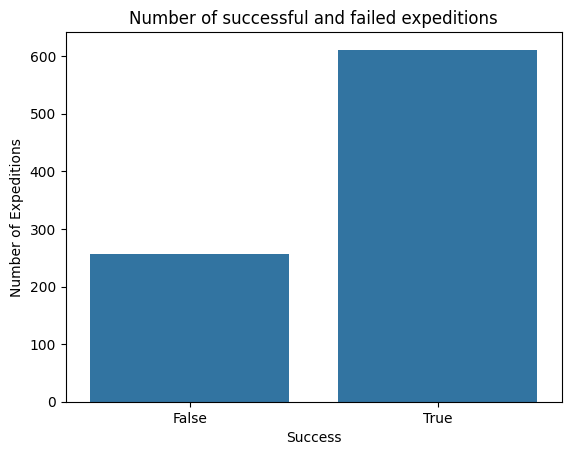

In [205]:
sns.countplot(x="success", data=df)
plt.title("Number of successful and failed expeditions")
plt.xlabel("Success")
plt.ylabel("Number of Expeditions")

print("Average success rate:", df["success"].mean() * 100)

#most expeditions were successful(70.4%), but failure is not rare(29.6%).

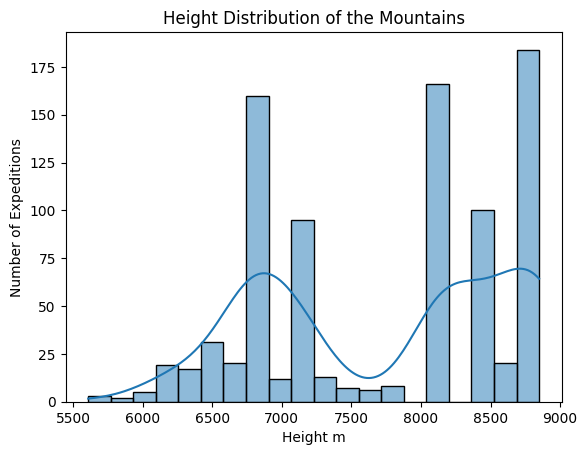

Expeditions on mountains over 8000m: 54.14746543778802


In [206]:
sns.histplot(df["height_m"], bins=20, edgecolor="black", kde=True)
plt.title("Height Distribution of the Mountains")
plt.xlabel("Height m")
plt.ylabel("Number of Expeditions")
plt.show()

print("Expeditions on mountains over 8000m:", (df["height_m"] >= 8000).mean() * 100)

#the expeditions are mostly on a specific mountains. and the distribution shows
#two groups of mountains the first is around 6000m - 7500m and the second is above 8000m.
#and more than half of the expeditions(54%) are on the mountains above 800m.

Expeditions on speinr and autumn: 97.00460829493088


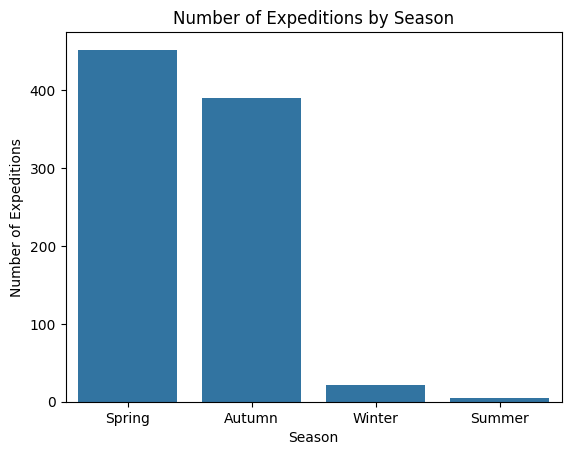

In [207]:
sns.countplot(x="season", data=df)
plt.title("Number of Expeditions by Season")
plt.xlabel("Season")
plt.ylabel("Number of Expeditions")

print("Expeditions on speinr and autumn:", ((df["season"] == "Spring") | (df["season"] == "Autumn")).mean() * 100)

#most expeditions were held in spring and autumn seasons(97%)

In [240]:
# Upper bound for outliers
def upper_bound(column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    return q3 + 1.5 * iqr

Median team size: 6.0
Teams above the upper bound: 29
Big teams: 1.0
All teams: 0.8918128654970761


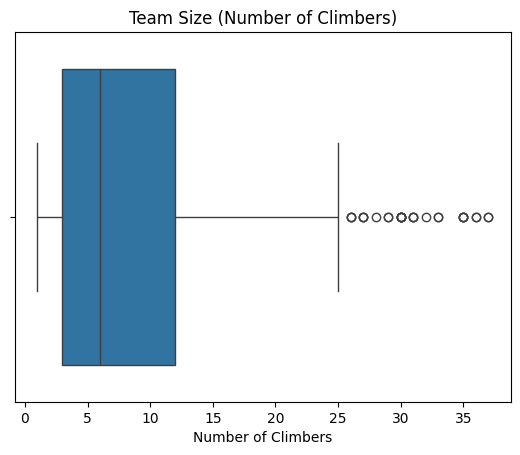

In [ ]:
sns.boxplot(x=df["members"])
plt.title("Team Size (Number of Climbers)")
plt.xlabel("Number of Climbers")

upper = upper_bound("members")

print("Median team size:", df["members"].median())

print("Teams above the upper bound:", (df["members"] > upper).sum())

#check if the outliers are errors: usually guides for each climber
df["guides_per_climber"] = df["hired_staff"] / df["members"]

print("Big teams:", df[df["members"] > 25]["guides_per_climber"].median())
print("All teams:", df["guides_per_climber"].median())

#most teams have between 3 and 12 climbers, and the median is 6.
#the distribution is right skewed, because some teams are bigger than upper bound (29 teams).
#the outliers are not errors, because usually there is about one guide for each climber.

Median hired staff: 5.0
Expeditions above the upper bound: 70
Median team size (big staff): 20.5
Median team size (all): 6.0


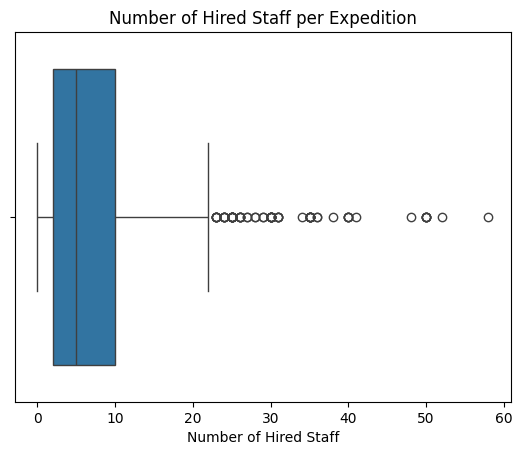

In [ ]:
sns.boxplot(x=df["hired_staff"])
plt.title("Number of Hired Staff per Expedition")
plt.xlabel("Number of Hired Staff")

upper = upper_bound("hired_staff")

print("Median hired staff:", df["hired_staff"].median())
print("Expeditions above the upper bound:", (df["hired_staff"] > upper).sum())   # 70
big = df[df["hired_staff"] > upper]
print("Median team size (big staff):", big["members"].median())
print("Median team size (all):", df["members"].median())

#most teams have between 2 and 10 guides, and the median is 5.
#the distribution is right skewed, because some teams hired more guides than upper bound (70 teams).
#the outliers are not errors, because expeditions with many staff also have many 
#climbers (about 20 climbers, while a normal expedition has 6).

Known values: 333
Median days: 21.0


,peak,height_m,year,season,members,success,end_reason,total_days
173,Everest,8849,2021,Winter,1,False,"Bad weather (storms, high winds)",76.0


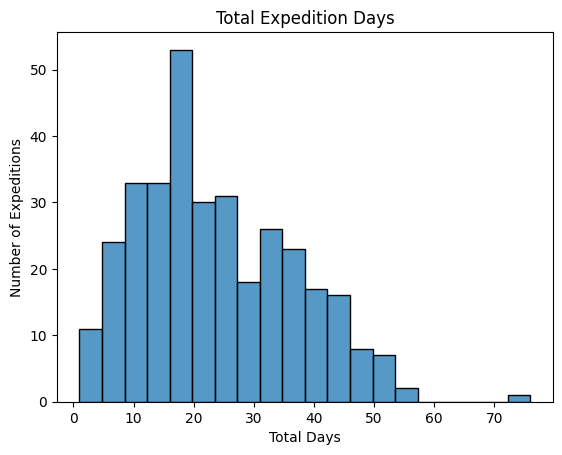

In [251]:
sns.histplot(df["total_days"], bins=20)
plt.title("Total Expedition Days")
plt.xlabel("Total Days")
plt.ylabel("Number of Expeditions")

print("Known values:", df["total_days"].notnull().sum())
print("Median days:", df["total_days"].median())

#check the outlier
df[df["total_days"] > 60][["peak","height_m", "year", "season", "members", "success", "end_reason", "total_days"]]

#most expeditions take between 10 and 45 days, and the median is 21 days. 
#the distribution is right-skewed, with one long trip of 76 days. 
#this outlier is not an error, it was a solo winter attempt on Everest that stopped because of bad weather.
#note: this is based on only 333 expeditions, because 60% of the values are missing.

Number of nationalities: 64
Top 10 share: 65.66820276497695


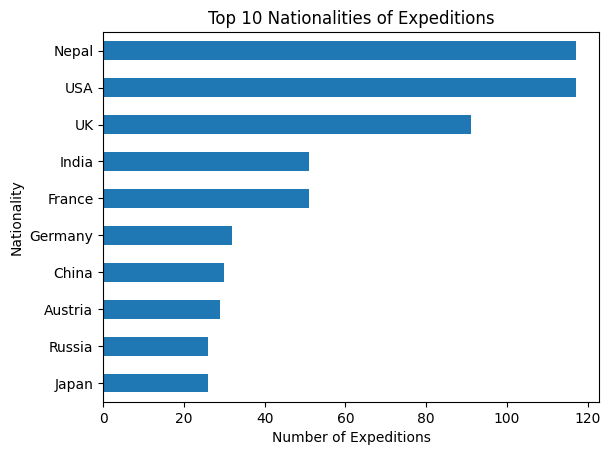

In [ ]:
top10 = df["nationality"].value_counts().head(10)

top10.plot(kind="barh")
plt.title("Top 10 Nationalities of Expeditions")
plt.xlabel("Number of Expeditions")
plt.ylabel("Nationality")
plt.gca().invert_yaxis()

print("Number of nationalities:", df["nationality"].nunique())
print("Top 10 share:", top10.sum() / len(df) * 100)

#climbers come from 64 different countries, but the top 10 make up about 66% of all expeditions.

Number of agencies: 182
Agencies with only 1 expedition: 96


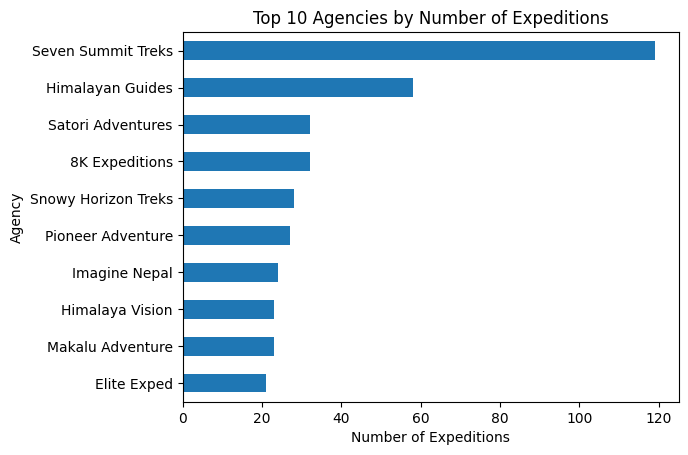

In [ ]:
agencies = df[df["agency"] != "Unknown"]
top10 = agencies["agency"].value_counts().head(10)

top10.plot(kind="barh")
plt.title("Top 10 Agencies by Number of Expeditions")
plt.xlabel("Number of Expeditions")
plt.ylabel("Agency")
plt.gca().invert_yaxis()

print("Number of agencies:", df["agency"].nunique())
print("Agencies with only 1 expedition:", (df["agency"].value_counts() == 1).sum())

#there are 182 agencies, but most of them are small (96 agencies) organized only one expedition
#Seven Summit Treks is the biggest, which is about twice the second agency Himalayan Guides.

oxygen_used
False    0.543779
True     0.456221
Name: proportion, dtype: float64


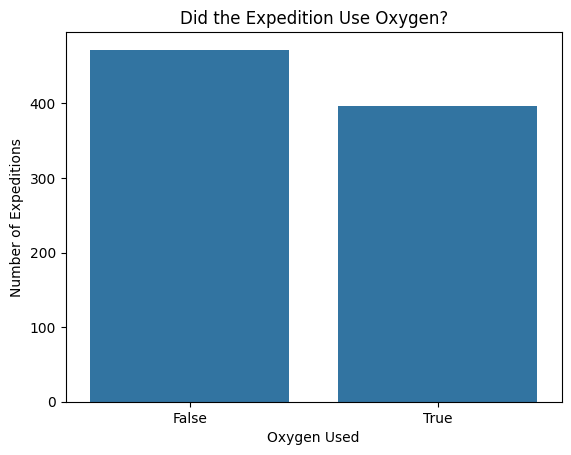

In [263]:
sns.countplot(x="oxygen_used", data=df)
plt.title("Did the Expedition Use Oxygen?")
plt.xlabel("Oxygen Used")
plt.ylabel("Number of Expeditions")

print(df["oxygen_used"].value_counts(normalize=True))

#46% of the expeditions used oxygen and 54% did not.
#so the data is almost balanced, which is good for 
#comparing success with and without oxygen later.

Expeditions with at least one death: 37


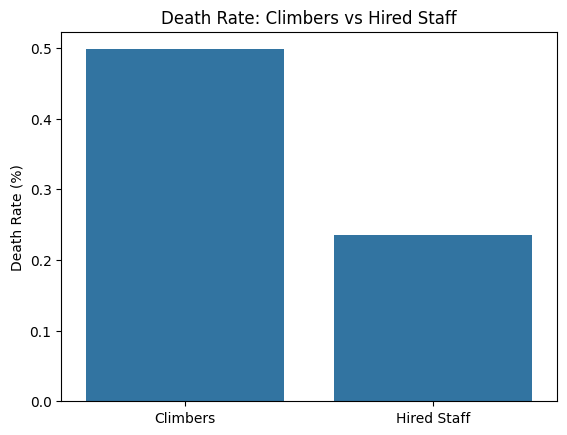

In [273]:
deaths = pd.DataFrame({
    "group": ["Climbers", "Hired Staff"],
    "death_rate": [df["member_deaths"].sum() / df["members"].sum() * 100,
                   df["hired_deaths"].sum() / df["hired_staff"].sum() * 100]
})

sns.barplot(x="group", y="death_rate", data=deaths)
plt.title("Death Rate: Climbers vs Hired Staff")
plt.xlabel("")
plt.ylabel("Death Rate (%)")

print("Expeditions with at least one death:", ((df["member_deaths"] + df["hired_deaths"]) > 0).sum())

#deaths are rare, only 37 expeditions (about 4%) had at least one death.
#the death rate for climbers (about 0.5%) is about twice the rate for hired staff (about 0.25%).

### Bivariate analysis

In [216]:
Crosstab = pd.crosstab(df["success"], df["oxygen_used"])

Crosstab

oxygen_used,False,True
success,,
False,213,44
True,259,352


In [217]:
#did the expedition have any death?
df["any_death"] = (df["member_deaths"] + df["hired_deaths"]) > 0

#number of guides for each climber
df["guides_per_climber"] = df["hired_staff"] / df["members"]

#group the team size
df["team_size"] = pd.cut(df["members"], bins=[0, 1, 3, 6, 12, 100],
                         labels=["Solo", "2-3", "4-6", "7-12", "13+"])

#group the mountain height
df["height_group"] = pd.cut(df["height_m"], bins=[0, 7000, 8000, 9000],
                            labels=["Under 7,000 m", "7,000-8,000 m", "Over 8,000 m"])

<Axes: xlabel='height_group', ylabel='success'>

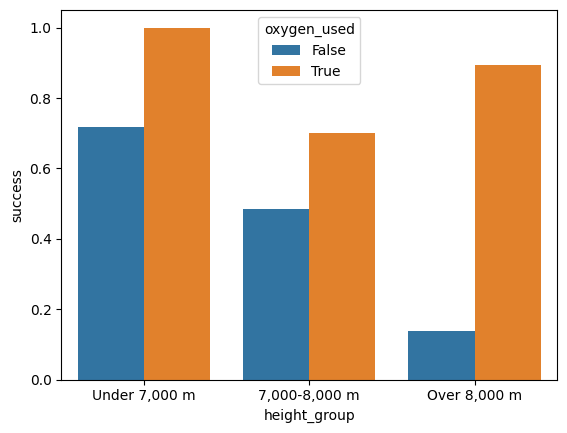

In [218]:
sns.barplot(x="height_group", y="success", hue="oxygen_used", data=df, errorbar=None)

<Axes: xlabel='team_size', ylabel='success'>

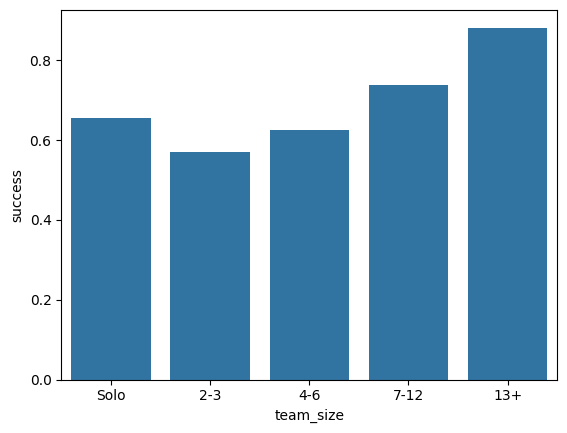

In [219]:
sns.barplot(x="team_size", y="success", data=df, errorbar=None)

<Axes: xlabel='members', ylabel='hired_staff'>

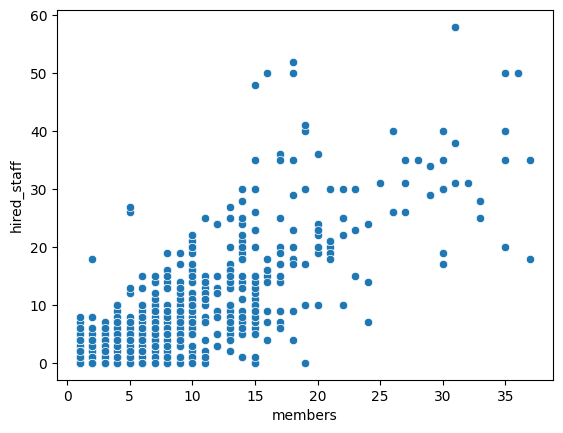

In [220]:
#sns.scatterplot(x="members", y="hired_staff", hue="success", data=df)
sns.scatterplot(x="members", y="hired_staff", data=df)


In [221]:
#success rate for expeditions with and without guides
print(df.groupby(df["hired_staff"] > 0)["success"].mean())

hired_staff
False    0.429577
True     0.757576
Name: success, dtype: float64


<Axes: xlabel='season', ylabel='success'>

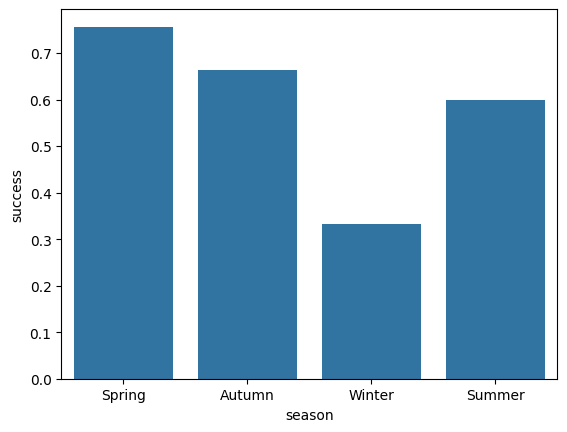

In [222]:
sns.barplot(x="season", y="success", data=df, errorbar=None)

<Axes: xlabel='season', ylabel='any_death'>

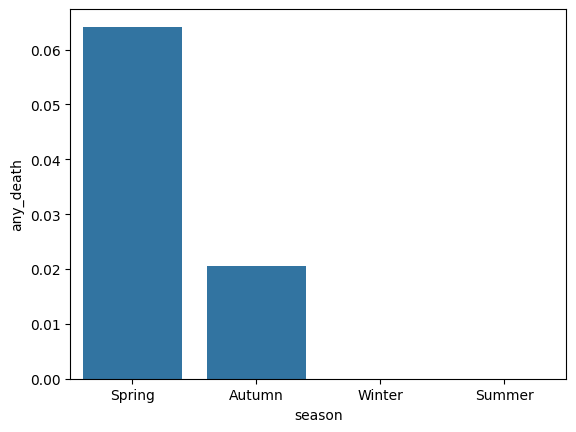

In [223]:
sns.barplot(x="season", y="any_death", data=df, errorbar=None)

<Axes: xlabel='height_group', ylabel='success'>

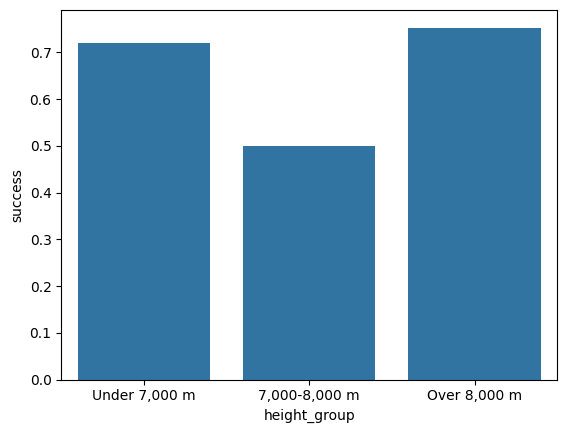

In [224]:
sns.barplot(x="height_group", y="success", data=df, errorbar=None)

<Axes: xlabel='height_group', ylabel='any_death'>

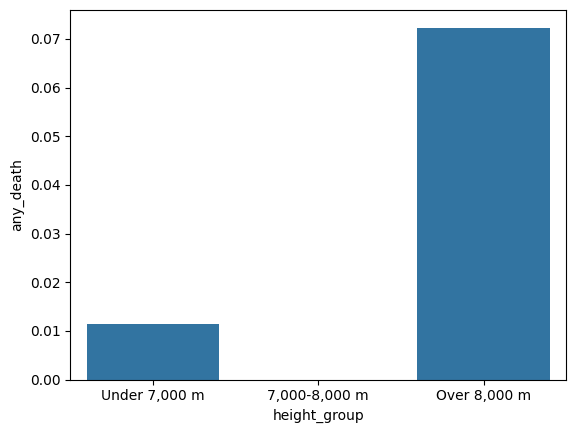

In [225]:
sns.barplot(x="height_group", y="any_death", data=df, errorbar=None)

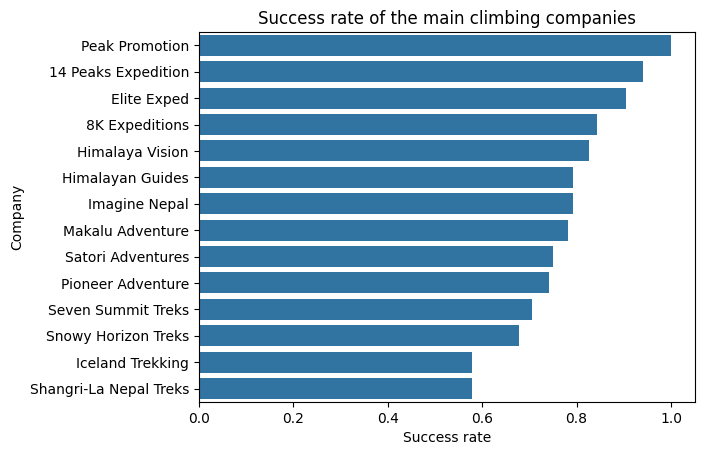

In [226]:
#success rate of companies with at least 15 expeditions
company = df[df["agency"] != "Unknown"].groupby("agency")["success"].agg(["mean", "count"])
company = company[company["count"] >= 15].sort_values("mean", ascending=False)

sns.barplot(x=company["mean"], y=company.index)
plt.title("Success rate of the main climbing companies")
plt.xlabel("Success rate")
plt.ylabel("Company")
plt.show()

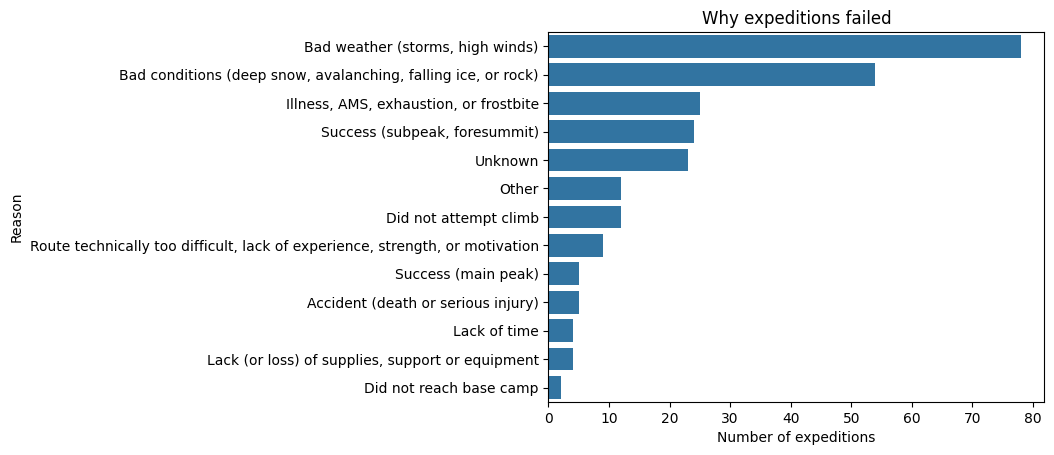

In [227]:
#reasons why failed expeditions ended
failed = df[df["success"] == False]
reasons = failed["end_reason"].value_counts()

sns.barplot(x=reasons.values, y=reasons.index)
plt.title("Why expeditions failed")
plt.xlabel("Number of expeditions")
plt.ylabel("Reason")
plt.show()

<Axes: xlabel='commercial_route', ylabel='success'>

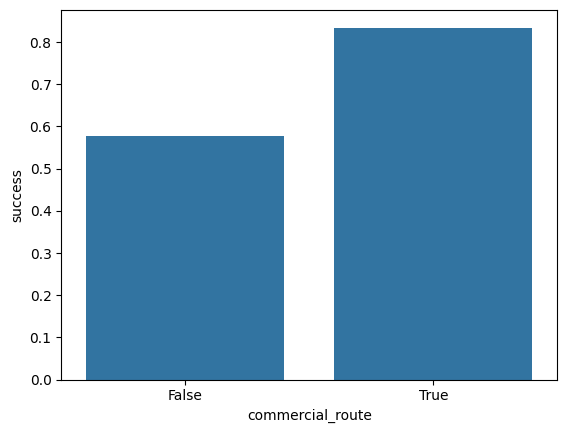

In [228]:
sns.barplot(x="commercial_route", y="success", data=df, errorbar=None)

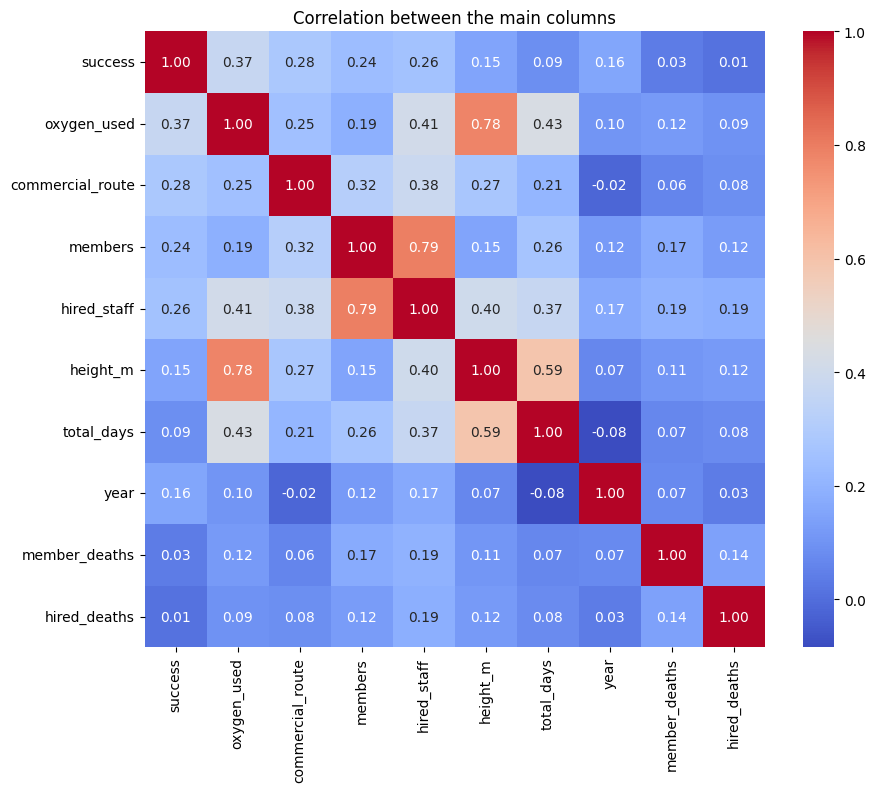

In [229]:
cols = ["success", "oxygen_used", "commercial_route", "members", "hired_staff",
        "height_m", "total_days", "year", "member_deaths", "hired_deaths"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[cols].astype(float).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between the main columns")
plt.show()

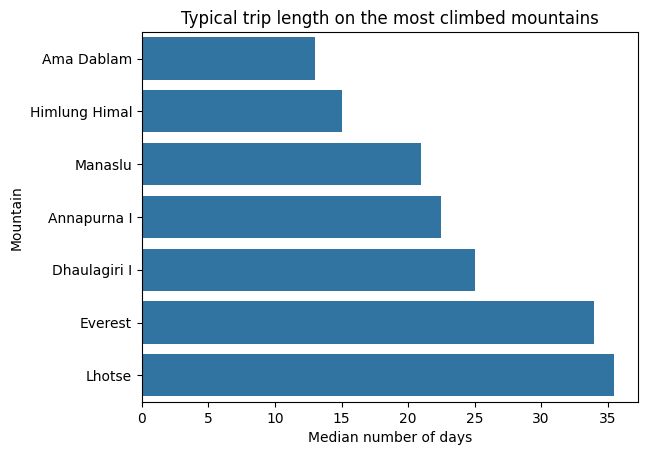

In [230]:
#typical trip length on mountains with at least 10 known trips
days = df.groupby("peak")["total_days"].agg(["median", "count"])
days = days[days["count"] >= 10].sort_values("median")

sns.barplot(x=days["median"], y=days.index)
plt.title("Typical trip length on the most climbed mountains")
plt.xlabel("Median number of days")
plt.ylabel("Mountain")
plt.show()

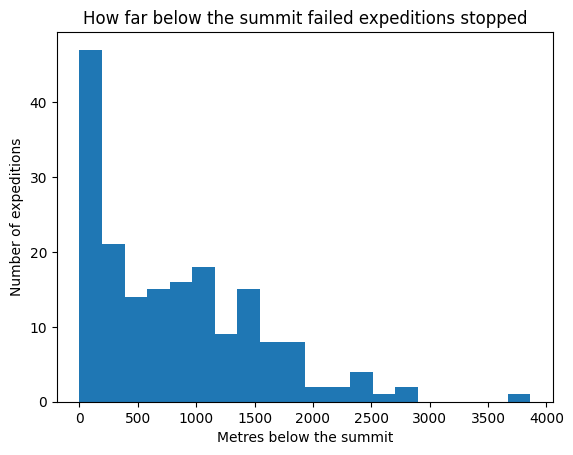

In [231]:
#how far below the summit did failed expeditions stop?
failed = df[(df["success"] == False) & (df["highpoint_m"].notna())].copy()
failed["metres_below_summit"] = failed["height_m"] - failed["highpoint_m"]

plt.hist(failed["metres_below_summit"], bins=20)
plt.title("How far below the summit failed expeditions stopped")
plt.xlabel("Metres below the summit")
plt.ylabel("Number of expeditions")
plt.show()

In [232]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

#height in km, so the numbers are on a similar scale to the other columns
df["height_km"] = df["height_m"] / 1000

#features (decided before the trip) and target
X = df[["oxygen_used", "members", "hired_staff", "height_km", "season", "commercial_route"]]
X = pd.get_dummies(X, columns=["season"], drop_first=True)   #one-hot encoding for season
y = df["success"]

#80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [233]:
y_pred = model.predict(X_test)   #model predicts success (True) or failure (False)

print("Accuracy:", accuracy_score(y_test, y_pred))     #percentage of correct predictions
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))                 #[[TN, FP], [FN, TP]]
print("Precision:", precision_score(y_test, y_pred))   #out of all predicted success, how many really succeeded
print("Recall:", recall_score(y_test, y_pred))         #how many real successes the model found

#weight of each feature
print(pd.Series(model.coef_[0], index=X.columns))

Accuracy: 0.7701149425287356
Confusion matrix:
[[ 25  28]
 [ 12 109]]
Precision: 0.7956204379562044
Recall: 0.9008264462809917
oxygen_used         2.708911
members             0.075731
hired_staff         0.016060
height_km          -1.120924
commercial_route    0.963848
season_Spring       0.473398
season_Summer       0.017437
season_Winter      -0.471414
dtype: float64
